# Overview
> **Chuyển đổi từ `1. MLP/MNIST_MLP.ipynb` sang PyTorch (sử dụng bộ dữ liệu MNIST thật)**
- Goal: recognizing handwritten digits (28x28 -> 10 classes)
- Architecture: Flatten -> Linear(512, ReLU) -> Dropout(0.2) -> Linear(512, ReLU) -> Dropout(0.2) -> Linear(10)


In [1]:
import time
from pathlib import Path
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_classes = 10


# (1) Data (Real MNIST dataset)


In [2]:
def load_mnist():
    for p in [Path('../../data/mnist.npz'), Path('mnist.npz')]:
        if p.exists():
            with np.load(p) as f:
                return (f['x_train'], f['y_train']), (f['x_test'], f['y_test'])
    Path('mnist.npz').parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve('https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz', 'mnist.npz')
    with np.load('mnist.npz') as f:
        return (f['x_train'], f['y_train']), (f['x_test'], f['y_test'])

(x_train, y_train), (x_test, y_test) = load_mnist()
x_train = (x_train.astype('float32') / 255.0).reshape(-1, 28, 28)
x_test = (x_test.astype('float32') / 255.0).reshape(-1, 28, 28)
print(x_train.shape[0], 'train samples |', x_test.shape[0], 'test samples')

train_loader = DataLoader(TensorDataset(torch.tensor(x_train), torch.tensor(y_train, dtype=torch.long)), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.tensor(x_test), torch.tensor(y_test, dtype=torch.long)), batch_size=256, shuffle=False)


60000 train samples | 10000 test samples


# (2) Declare model (`MNIST_MLP` + feature extraction)


In [3]:
class MNIST_MLP(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Dropout(0.2))
        self.fc2 = nn.Sequential(nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.2))
        self.fc3 = nn.Linear(512, num_classes)

    def forward(self, x, return_fc2=False):
        x = self.flatten(x)
        x = self.fc1(x)
        feat = self.fc2(x)
        logits = self.fc3(feat)
        return (feat, logits) if return_fc2 else logits

model = MNIST_MLP(num_classes).to(device)
print(model)
print('Total trainable params:', sum(p.numel() for p in model.parameters() if p.requires_grad))


MNIST_MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (fc2): Sequential(
    (0): Linear(in_features=512, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (fc3): Linear(in_features=512, out_features=10, bias=True)
)
Total trainable params: 669706


# (3) Train defined model


In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
epochs = 10
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

t0 = time.time()
for epoch in range(1, epochs + 1):
    model.train()
    tr_loss, tr_correct = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * len(xb)
        tr_correct += (out.argmax(1) == yb).sum().item()

    model.eval()
    va_loss, va_correct = 0.0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            va_loss += criterion(out, yb).item() * len(xb)
            va_correct += (out.argmax(1) == yb).sum().item()

    history['train_loss'].append(tr_loss / len(x_train))
    history['val_loss'].append(va_loss / len(x_test))
    history['train_acc'].append(tr_correct / len(x_train))
    history['val_acc'].append(va_correct / len(x_test))
    if epoch in [1, 3, 6, 10]:
        print(f'Epoch {epoch:02d}/{epochs} | Train Acc: {history["train_acc"][-1]*100:.2f}% | Test Acc: {history["val_acc"][-1]*100:.2f}%')

print('> training time is %.4f minutes' % ((time.time() - t0)/60))


Epoch 01/10 | Train Acc: 88.49% | Test Acc: 96.09%


Epoch 03/10 | Train Acc: 97.31% | Test Acc: 97.35%


Epoch 06/10 | Train Acc: 98.58% | Test Acc: 98.18%


Epoch 10/10 | Train Acc: 99.17% | Test Acc: 98.11%
> training time is 0.8396 minutes


# (4) Evaluate trained model & Intermediate feature inspection


Test loss: 0.0618
Test accuracy: 0.9811


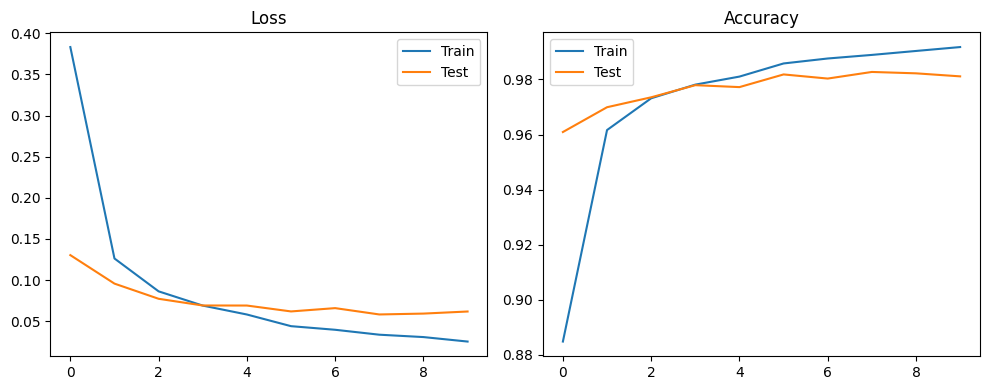

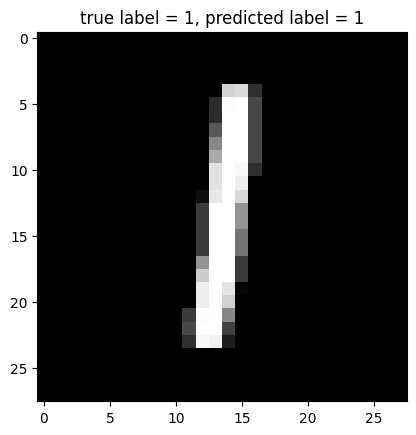

fc2 feature shape: (1, 512) | prob sum: 1.0


In [5]:
print('Test loss:', round(history['val_loss'][-1], 4))
print('Test accuracy:', round(history['val_acc'][-1], 4))

plt.figure(figsize=(10, 4))
plt.subplot(121); plt.plot(history['train_loss'], label='Train'); plt.plot(history['val_loss'], label='Test'); plt.title('Loss'); plt.legend()
plt.subplot(122); plt.plot(history['train_acc'], label='Train'); plt.plot(history['val_acc'], label='Test'); plt.title('Accuracy'); plt.legend()
plt.tight_layout(); plt.show()

idx = np.random.choice(len(x_test))
test_img = x_test[idx]
model.eval()
with torch.no_grad():
    y_feat, logits = model(torch.tensor(test_img).unsqueeze(0).to(device), return_fc2=True)
    probs = torch.softmax(logits, dim=1)
    pred_label = probs.argmax(1).item()

plt.imshow(test_img, cmap='gray')
plt.title(f'true label = {y_test[idx]}, predicted label = {pred_label}')
plt.show()
print('fc2 feature shape:', tuple(y_feat.shape), '| prob sum:', round(probs.sum().item(), 4))
